Step 0 | NLL: 4.9069
Step 500 | NLL: 3.9318
Step 1000 | NLL: 3.9368
Early stopping at step 1184

Model Comparison:
GMM Log-Likelihood: -3784.3647
Flow Log-Likelihood: -5620.4434
GMM KL Divergence: 15.3746
Flow KL Divergence: 36.1072


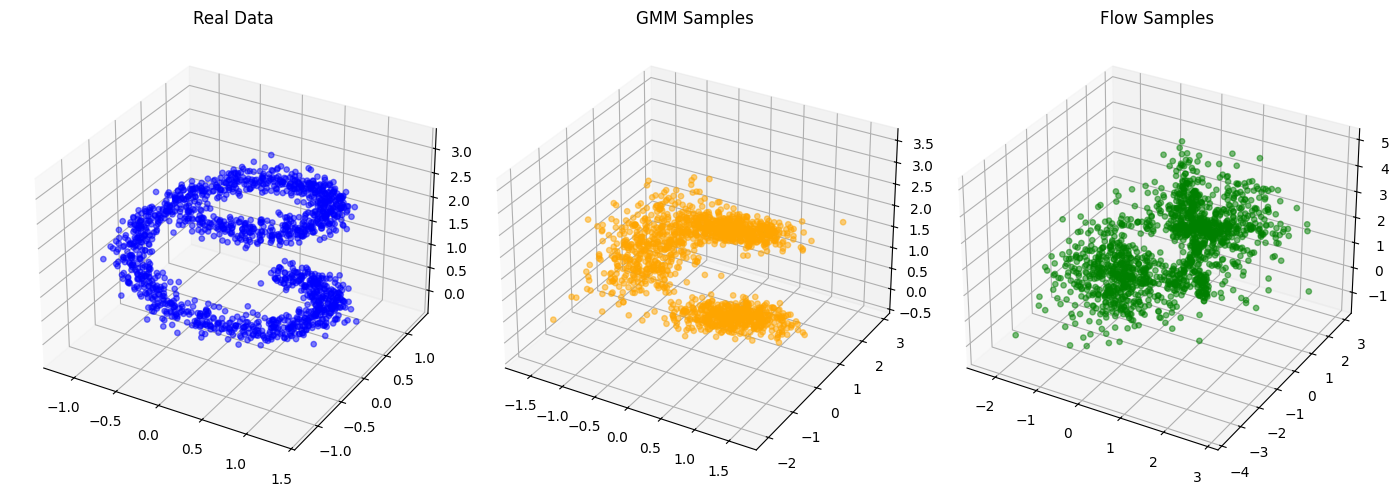

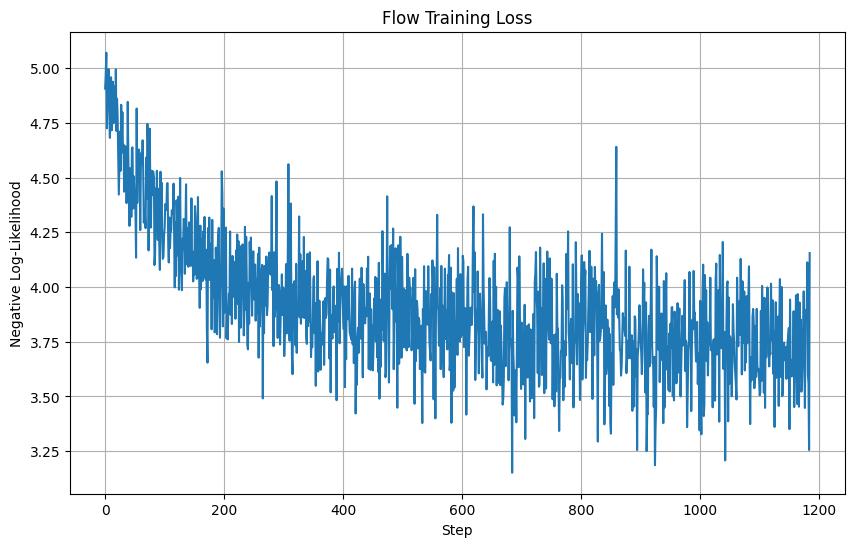

In [ ]:
!pip install nflows==0.14

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from nflows.flows.base import Flow
from nflows.transforms import CompositeTransform, ReversePermutation, PiecewiseRationalQuadraticCouplingTransform
from nflows.nn.nets import ResidualNet
from scipy.stats import gaussian_kde
from mpl_toolkits.mplot3d import Axes3D

# Set seeds
np.random.seed(42)
torch.manual_seed(42)

# ==== 1. Generate 3D banana-shaped data ====
n_samples = 1500
theta = np.linspace(0, 3 * np.pi, n_samples)
x = np.sin(theta) + 0.1 * np.random.randn(n_samples)
y = np.cos(theta) + 0.1 * np.random.randn(n_samples)
z = theta / (3 * np.pi) * 3 + 0.1 * np.random.randn(n_samples)  # A smooth increasing 'height' dimension
data_3d = np.vstack([x, y, z]).T

# Normalize data
scaler = StandardScaler()
data_3d_scaled = scaler.fit_transform(data_3d)

# ==== 2. Fit GMM ====
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm.fit(data_3d_scaled)
gmm_log_likelihood = gmm.score(data_3d_scaled) * len(data_3d_scaled)

# ==== 3. Custom Base Distribution for Flow ====
class CustomMixtureOfGaussians(torch.distributions.Distribution):
    arg_constraints = {}
    def __init__(self, means, variances, weights, input_dim=3, device='cpu'):
        super().__init__(validate_args=False)
        self.input_dim = input_dim
        self.distributions = [
            torch.distributions.MultivariateNormal(
                torch.tensor(m, dtype=torch.float32, device=device),
                torch.diag(torch.tensor(v, dtype=torch.float32, device=device))
            ) for m, v in zip(means, variances)
        ]
        self.weights = torch.tensor(weights, dtype=torch.float32, device=device)

    def log_prob(self, x, context=None):
        log_probs = torch.stack([d.log_prob(x) + torch.log(w) for d, w in zip(self.distributions, self.weights)], dim=0)
        return torch.logsumexp(log_probs, dim=0)

    def sample(self, sample_shape, context=None):
        if isinstance(sample_shape, int):
            sample_shape = (sample_shape,)
        z = torch.multinomial(self.weights, sample_shape[0], replacement=True)
        samples = torch.stack([self.distributions[i].sample(sample_shape) for i in range(len(self.distributions))])
        return samples[z, torch.arange(sample_shape[0])]

# ==== 4. Define flow model ====
def create_flow(input_dim=3, hidden_features=128, num_layers=6):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    transforms = []
    # Alternate masks of zeros and ones for coupling layers
    masks = [torch.tensor([(i + j) % 2 for i in range(input_dim)], dtype=torch.float32, device=device) for j in range(num_layers)]
    for mask in masks:
        transforms.append(ReversePermutation(features=input_dim))
        transforms.append(
            PiecewiseRationalQuadraticCouplingTransform(
                mask=mask,
                transform_net_create_fn=lambda in_features, out_features: ResidualNet(
                    in_features=in_features,
                    out_features=out_features,
                    hidden_features=hidden_features,
                    num_blocks=3,
                    activation=nn.ReLU()
                ),
                tails='linear',
                num_bins=8
            )
        )
    base_dist = CustomMixtureOfGaussians(
        means=[[-1.0]*input_dim, [1.0]*input_dim],
        variances=[[1.0]*input_dim, [1.0]*input_dim],
        weights=[0.5, 0.5],
        input_dim=input_dim,
        device=device
    )
    transform = CompositeTransform(transforms)
    flow = Flow(transform, base_dist).to(device)
    return flow

def train_flow(flow, data, steps=5000, lr=5e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    flow = flow.to(device)
    optimizer = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2000, gamma=0.5)
    data_tensor = torch.tensor(data, dtype=torch.float32).to(device)
    losses = []
    batch_size = 64
    best_loss = float('inf')
    patience = 500
    steps_without_improvement = 0
    for step in range(steps):
        idx = np.random.choice(len(data), size=batch_size, replace=False)
        batch = data_tensor[idx]
        log_prob = flow.log_prob(batch)
        loss = -log_prob.mean()
        if not torch.isfinite(loss):
            print(f"Non-finite loss at step {step}")
            break
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(flow.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        if step % 500 == 0:
            print(f"Step {step} | NLL: {loss.item():.4f}")
        if loss.item() < best_loss:
            best_loss = loss.item()
            steps_without_improvement = 0
        else:
            steps_without_improvement += 1
            if steps_without_improvement >= patience:
                print(f"Early stopping at step {step}")
                break
    flow_log_likelihood = flow.log_prob(data_tensor).sum().item()
    return flow, losses, flow_log_likelihood

# ==== 5. Train the flow ====
flow = create_flow(input_dim=3)
flow, losses, flow_log_likelihood = train_flow(flow, data_3d_scaled)

# ==== 6. Evaluate KL divergence ====
def compute_kl_divergence(real_data, generated_data):
    kl_scores = []
    for i in range(real_data.shape[1]):
        kde_real = gaussian_kde(real_data[:, i])
        kde_gen = gaussian_kde(generated_data[:, i])
        xs = np.linspace(
            min(real_data[:, i].min(), generated_data[:, i].min()),
            max(real_data[:, i].max(), generated_data[:, i].max()), 1000
        )
        p = np.clip(kde_real(xs), 1e-10, 1)
        q = np.clip(kde_gen(xs), 1e-10, 1)
        kl = np.sum(p * np.log(p / q))
        kl_scores.append(kl)
    return np.mean(kl_scores)

# Generate samples
gmm_samples_scaled = gmm.sample(len(data_3d_scaled))[0]
flow_samples_scaled = flow.sample(len(data_3d_scaled)).detach().cpu().numpy()

# Inverse transform to original scale
data_3d_original = scaler.inverse_transform(data_3d_scaled)
gmm_samples = scaler.inverse_transform(gmm_samples_scaled)
flow_samples = scaler.inverse_transform(flow_samples_scaled)

# Calculate KL divergences
gmm_kl = compute_kl_divergence(data_3d_original, gmm_samples)
flow_kl = compute_kl_divergence(data_3d_original, flow_samples)

# ==== 7. Results ====
print("\nModel Comparison:")
print(f"GMM Log-Likelihood: {gmm_log_likelihood:.4f}")
print(f"Flow Log-Likelihood: {flow_log_likelihood:.4f}")
print(f"GMM KL Divergence: {gmm_kl:.4f}")
print(f"Flow KL Divergence: {flow_kl:.4f}")

# ==== 8. Visualize 3D data ====
fig = plt.figure(figsize=(14, 6))

ax = fig.add_subplot(131, projection='3d')
ax.scatter(data_3d_original[:, 0], data_3d_original[:, 1], data_3d_original[:, 2], c='blue', alpha=0.5, s=15)
ax.set_title("Real Data")

ax = fig.add_subplot(132, projection='3d')
ax.scatter(gmm_samples[:, 0], gmm_samples[:, 1], gmm_samples[:, 2], c='orange', alpha=0.5, s=15)
ax.set_title("GMM Samples")

ax = fig.add_subplot(133, projection='3d')
ax.scatter(flow_samples[:, 0], flow_samples[:, 1], flow_samples[:, 2], c='green', alpha=0.5, s=15)
ax.set_title("Flow Samples")

plt.tight_layout()
plt.show()

# ==== 9. Plot training loss ====
plt.figure(figsize=(10, 6))
plt.plot(losses)
plt.title("Flow Training Loss")
plt.xlabel("Step")
plt.ylabel("Negative Log-Likelihood")
plt.grid(True)
plt.show()
